# Економіка

Потік каменів духу і пігулок за ботами (tech 6.2, «потік валюти»). Камені — валюта (D17); джерела — події, чутки й здобич боїв (`loot:grp.*`), витрати — події, крамниця (`shop`), відновлення пулу (`qi_restore`) і поповнення місця (`place_refill`).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from simruns import BOTS, label, load, ranks

RUNS, SEED_FROM = 1000, 1  # per bot; data regenerates by itself when Core, Sim.Cli or content changes
data = load(runs=RUNS, seed_from=SEED_FROM)
runs = data.runs
pd.options.display.float_format = "{:.2f}".format
plt.rcParams["figure.figsize"] = (10, 4)


def named(df, axis=0):
    """Replaces content IDs in the index (axis=0) or columns (axis=1) with Ukrainian names."""
    return df.rename(index=label) if axis == 0 else df.rename(columns=label)


def per_run(long, value, by):
    """Mean of value per run for each bot, counting runs where it never happened as zero."""
    total = long.pivot_table(index=by, columns="bot", values=value, aggfunc="sum", fill_value=0)
    return total.div(runs.groupby("bot").size(), axis=1).reindex(columns=list(BOTS), fill_value=0)


## Камені за забіг

In [2]:
cols = ["stones_start", "stones_earned", "stones_spent", "stones_end"]
runs.groupby("bot")[cols].agg(["mean", "median"]).reindex(list(BOTS))

stones_start        stones_earned         stones_spent         \
                 mean median          mean  median         mean median   
bot                                                                      
cautious        30.00  30.00         13.68   12.00        43.58  42.00   
fighter         30.00  30.00       1083.58 1100.00       982.06 996.00   
random          30.00  30.00        253.30  255.00       276.49 279.00   

         stones_end         
               mean median  
bot                         
cautious       0.09   0.00  
fighter      131.52 127.00  
random         6.80   4.00

## Джерела каменів

Середньо каменів на забіг за джерелом.

In [3]:
earned = per_run(data.stones[data.stones.flow == "earned"], "amount", "source")
named(earned.sort_values(list(BOTS), ascending=False))

bot,cautious,fighter,random
source,,,
evt.settlement.herb_gathering_job,11.52,3.96,12.29
Духовна трава,0.97,0.30,6.63
loot:grp.beast.grey_wolves,0.65,251.57,43.43
Святилище меча,0.32,0.49,1.37
loot:grp.bandits.road,0.21,564.51,124.58
Останки культиватора,0.00,262.03,21.80
loot:grp.beast.river_serpent,0.00,0.54,0.74
loot:grp.undead.battlefield_ghosts,0.00,0.17,6.47
evt.settlement.herb_pavilion_tonic,0.00,0.00,10.76


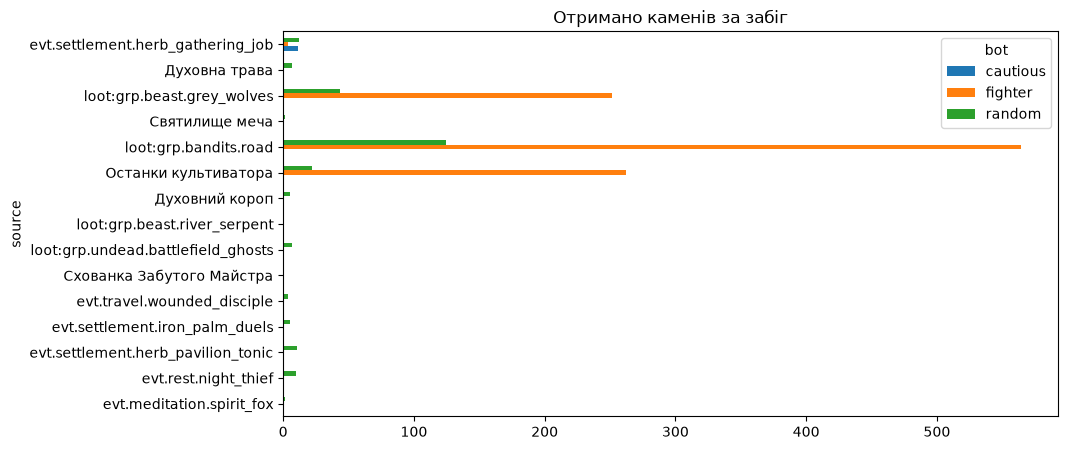

In [4]:
named(earned).sort_values("cautious").plot.barh(figsize=(10, 5), title="Отримано каменів за забіг");

## Витрати каменів

In [5]:
spent = per_run(data.stones[data.stones.flow == "spent"], "amount", "source")
named(spent.sort_values(list(BOTS), ascending=False))

bot,cautious,fighter,random
source,,,
shop,26.96,29.98,88.45
evt.travel.wandering_merchant,6.60,711.48,56.94
evt.travel.road_bandits,5.00,0.01,32.13
evt.travel.rival_cultivator,3.46,237.98,19.42
evt.settlement.merchant_tip,1.03,1.64,2.24
evt.settlement.tavern_brawl,0.53,0.96,1.15
place_refill,0.00,0.00,34.80
evt.rest.night_thief,0.00,0.00,22.49
qi_restore,0.00,0.00,11.80


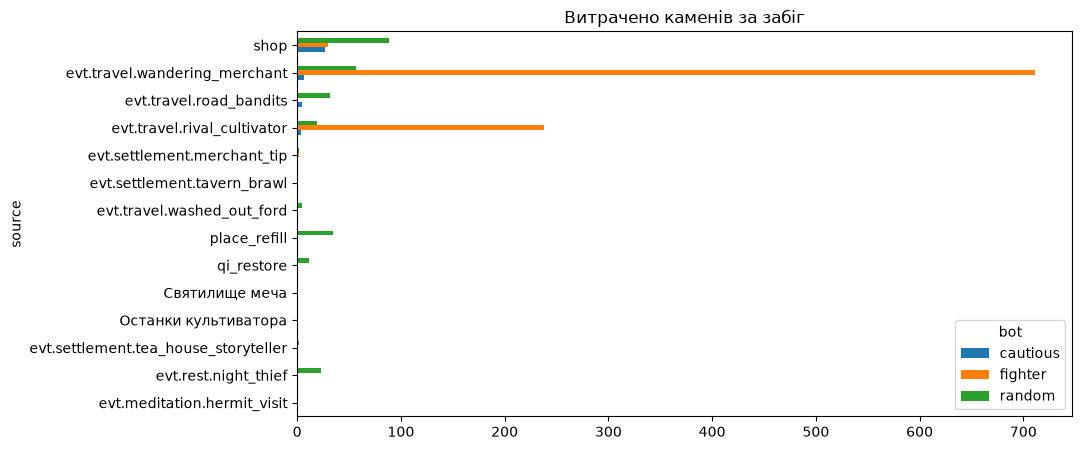

In [6]:
named(spent).sort_values("cautious").plot.barh(figsize=(10, 5), title="Витрачено каменів за забіг");

## Пігулки й фоліанти

Середньо куплено й прийнято за забіг (фоліанти лише купуються).

In [7]:
pills = data.pills.pivot_table(index="item", columns=["flow", "bot"], values="count", aggfunc="sum", fill_value=0)
named(pills.div(runs.groupby("bot").size(), axis=1, level="bot"))

flow                                  bought                   taken          \
bot                                 cautious fighter random cautious fighter   
item                                                                           
Фоліант методу лазурового подиху        0.00    0.00   0.05     0.00    0.00   
Фоліант стихії вогню                    0.00    0.00   0.63     0.00    0.00   
Фоліант «Пронизливий дракон»            0.00    1.00   0.66     0.00    0.00   
Пігулка зрощення кісток                 0.00    0.00   1.36     0.00    0.00   
Пігулка промивання кісткового мозку     0.00    0.00   0.00     0.00    0.00   
Пігулка заспокоєння меридіан            0.00    0.00   0.42     0.00    0.00   
Пігулка збирання ці                     2.25    0.83   1.94     4.91   13.20   
Пігулка духовної роси                   0.00    0.00   0.22     0.00    0.00   

flow                                        
bot                                 random  
item                                        
Фоліант методу лазурового подиху      0.00  
Фоліант стихії вогню                  0.00  
Фоліант «Пронизливий дракон»          0.00  
Пігулка зрощення кісток               0.89  
Пігулка промивання кісткового мозку   0.52  
Пігулка заспокоєння меридіан          0.40  
Пігулка збирання ці                  10.20  
Пігулка духовної роси                 0.22

## Токсини

Піковий рівень токсинів за забіг і токсини на момент успішного прориву залежно від рангу.

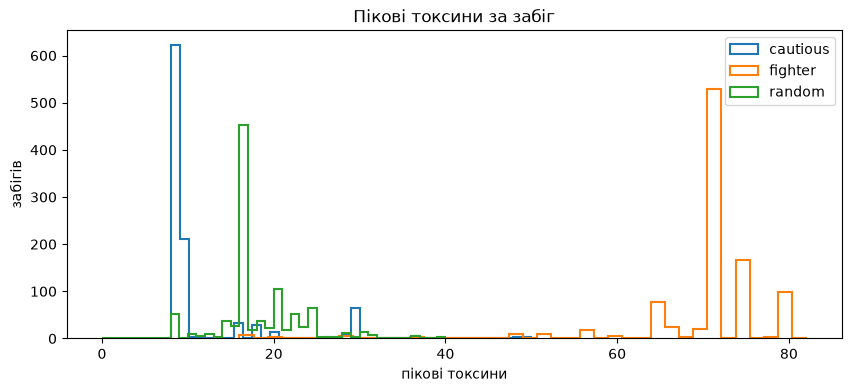

In [8]:
fig, ax = plt.subplots()
for bot in BOTS:
    ax.hist(runs.loc[runs.bot == bot, "peak_toxins"], bins=40, histtype="step", linewidth=1.5, label=bot)
ax.set(xlabel="пікові токсини", ylabel="забігів", title="Пікові токсини за забіг")
ax.legend();

In [9]:
bt = data.breakthroughs
ok = bt[bt.result == "success"]
order = [r for r in ranks() if r in set(ok["rank"])]
ok.groupby(["bot", "rank"]).toxins.describe()[["count", "mean", "50%", "max"]].reindex(order, level="rank").rename(index=label)

count  mean   50%   max
bot      rank                               
cautious Ущербний   885.00  2.05  0.00 30.00
         Звичайний 1014.00  0.26  0.00 16.00
         Добрий       3.00  0.00  0.00  0.00
fighter  Ущербний  1852.00 10.52 16.00 74.00
         Звичайний 1005.00 15.89 16.00 16.00
random   Ущербний   859.00  2.27  0.00 32.00
         Звичайний  848.00  2.44  0.00 24.00